# Stimulus representations

Four nested choices, each step justified by a measurement rather than by taste.

| | dims | adds |
|---|---|---|
| **S1** | 6 | bearing + a monotone proximity weight + condition + group size |
| **S2** | 7 | `outside` — the dot centroid is beyond the dish wall |
| **S3** `shoalr` | 13 | replaces the proximity **scalar** with a range **basis** |
| **S4** `shoal` | 18 | group size interacted with the range basis |

All bearings are `stim_angle_travel` — measured from the incoming chord, the frame a rollout
can reconstruct. Every channel is exactly 0 on no-stimulus bouts.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "clean_data").exists() and (ROOT.parent / "clean_data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from segment_bouts import load_physical_dish

PX_PER_MM, R0_MM, N_MAX = 3.60, 20.0, 8.0
BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "figure.dpi": 110, "legend.frameon": False})

d = pd.read_csv(ROOT / "clean_data" / "bouts_clean.csv")
dish = load_physical_dish(ROOT / "data" / "data" / "Original_data"
                          / "ROIdef2025-02-20T12_09_16.csv")
d["dot_r_norm"] = np.hypot(d.dot_cx - d.fish_id.map(dish["cx"]),
                           d.dot_cy - d.fish_id.map(dish["cy"])) / d.fish_id.map(dish["radius"])
d["outside"] = (d.dot_r_norm > 1.0).astype(float)
d["N"] = (d.n_dots_left.fillna(0) + d.n_dots_right.fillna(0))
d["g"] = 1.0 / (1.0 + (d.dot_dist_px / PX_PER_MM) / R0_MM)

# turn bouts with a defined bearing -- the population every plot below uses
t = d[d.dots_on & d.active & (d.dtheta_deg.abs() > 10) & d.stim_angle_travel.notna()].copy()
t["toward"] = (np.sign(t.dtheta_deg) == np.sign(t.stim_angle_travel)).astype(float)
print(f"{len(t):,} turn bouts with a bearing   ({100*t.outside.mean():.0f} % outside the dish)")


def curve(sub, edges, min_fish=8, min_n=25):
    """P(turn toward) per range bin: mean +/- 95% CI across FISH (the replicate unit)."""
    x, m, lo, hi = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        g = sub[sub.dot_dist_px.between(a, b)]
        per = g.groupby("fish_id").toward.agg(["mean", "size"])
        per = per[per["size"] >= min_n]["mean"]
        if len(per) < min_fish:
            continue
        se = per.std(ddof=1) / np.sqrt(len(per))
        x.append(np.sqrt(a * b) if a > 0 else b / 2)
        m.append(per.mean()); lo.append(per.mean() - 1.96 * se); hi.append(per.mean() + 1.96 * se)
    return np.array(x), np.array(m), np.array(lo), np.array(hi)


EDGES = np.array([0, 30, 45, 60, 80, 110, 150, 400])

35,006 turn bouts with a bearing   (11 % outside the dish)


## S1 · 6 dimensions

| # | column | definition |
|---|---|---|
| 1 | `act` | 1 when a dot is on screen and the bearing is defined, else 0. Gates every other channel. |
| 2 | `sin φ` | φ = bearing to the active-dot centroid, from the **incoming chord**. + = the fish's left. |
| 3 | `cos φ` | ahead (+1) vs behind (−1). |
| 4 | `g` | proximity weight `1 / (1 + r_mm / 20)`, monotone **decreasing** in range. |
| 5 | `moving` | 1 on moving-dot blocks, 0 on static. Block constant. |
| 6 | `nz` | group size, `log₂N / log₂8` ∈ (0, 1]. N ∈ {1, 2, 4, 6, 8}. |

Everything is bounded O(1) and 0 off-stimulus, so no scale fitting is needed.

## S2 · 7 dimensions — add `outside`

| # | column | definition |
|---|---|---|
| 1–6 | *as S1* | |
| 7 | `outside` | 1 when the dot centroid lies beyond the dish wall (`r/R > 1`), else 0. **11 %** of turn bouts. |

**Why it is not redundant with range.** If "outside" only meant "far away", the two curves
below would lie on top of each other once range is matched. They do not.

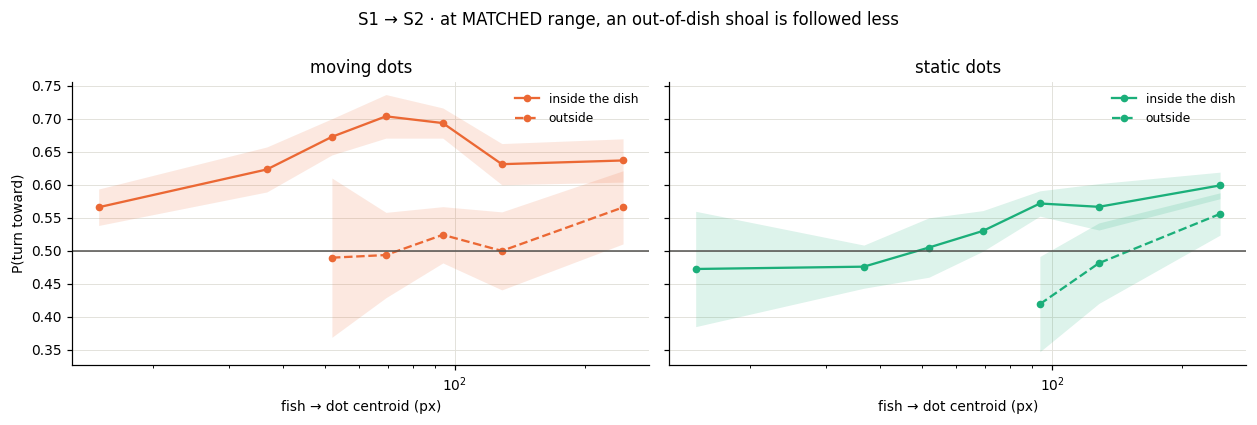

moving  pooled  inside 0.645  outside 0.531   |   at 60-85 px only: inside 0.699  outside 0.523  (gap -0.176)
static  pooled  inside 0.557  outside 0.502   |   at 60-85 px only: inside 0.549  outside 0.369  (gap -0.180)


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for j, (c, col) in enumerate((("moving", ORANGE), ("static", AQUA))):
    for outside, ls, lab in ((0.0, "-", "inside the dish"), (1.0, "--", "outside")):
        # the outside subset is thin, so relax the per-fish floor and let the CI show it
        x, m, lo, hi = curve(t[(t.cond == c) & (t.outside == outside)], EDGES,
                             min_fish=5, min_n=10)
        if len(x) == 0:
            continue
        ax[j].plot(x, m, ls, color=col, marker="o", ms=4, label=lab)
        ax[j].fill_between(x, lo, hi, color=col, alpha=.15, lw=0)
    ax[j].axhline(.5, color=INK2, lw=1)
    ax[j].set_xscale("log"); ax[j].set_xlabel("fish → dot centroid (px)")
    ax[j].set_title(f"{c} dots"); ax[j].legend(fontsize=8)
    ax[j].grid(color=GRID, lw=.6, zorder=0); ax[j].set_axisbelow(True)
ax[0].set_ylabel("P(turn toward)")
fig.suptitle("S1 → S2 · at MATCHED range, an out-of-dish shoal is followed less", y=1.0)
fig.tight_layout(); plt.show()

for c in ("moving", "static"):
    g = t[t.cond == c]
    a_, b_ = g[g.outside == 0], g[g.outside == 1]
    mid = g[g.dot_dist_px.between(60, 85)]
    ai, ao = mid[mid.outside == 0].toward.mean(), mid[mid.outside == 1].toward.mean()
    print(f"{c:<7} pooled  inside {a_.toward.mean():.3f}  outside {b_.toward.mean():.3f}"
          f"   |   at 60-85 px only: inside {ai:.3f}  outside {ao:.3f}  (gap {ao-ai:+.3f})")

The gap survives range-matching — at 60–85 px, moving drops **0.699 → 0.523** and static
**0.549 → 0.369**. So `outside` carries information a range channel cannot supply. It is also
the regime a re-anchored rollout will enter far more often than the rig did, since the rig
biased placement inward.

## S3 · `shoalr`, 13 dimensions — a range **basis** instead of `g`

| # | column | definition |
|---|---|---|
| 1 | `act` | dots present |
| 2 | `moving` | condition |
| 3 | `rz` | normalised log-range, `clip((ln r − ln 70) / ln 4, ±1)` — ±1 is ±2 octaves about 70 px |
| 4–7 | `G·sin φ` | bearing weighted by a 4-knot softmax basis over log r (knots **25, 50, 90, 160 px**) |
| 8–11 | `G·cos φ` | the same for the ahead/behind component |
| 12 | `moving·sin φ` | condition × bearing — lets the sign of the response flip between conditions |
| 13 | `moving·cos φ` | |

Since Σⱼ Gⱼ = 1, the basis already contains raw `sin φ` exactly, so `s`/`c` are redundant and
omitted. **Group size is dropped here** — that is what S4 restores.

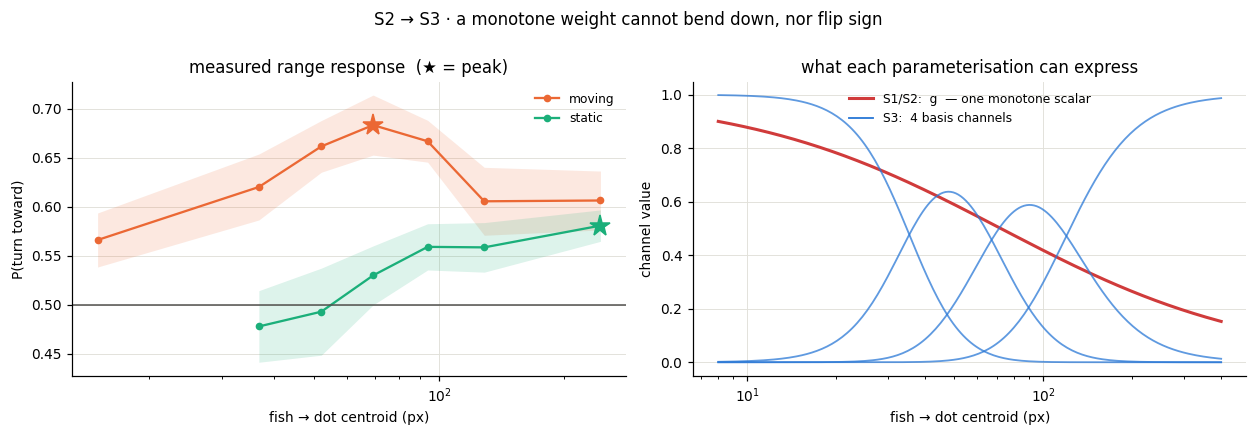

moving  0.568  0.630  0.662  0.685  0.665  0.597  0.598
static  0.484  0.475  0.488  0.538  0.568  0.558  0.582


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
for c, col in (("moving", ORANGE), ("static", AQUA)):
    x, m, lo, hi = curve(t[t.cond == c], EDGES)
    ax[0].plot(x, m, "-o", color=col, ms=4, label=c)
    ax[0].fill_between(x, lo, hi, color=col, alpha=.15, lw=0)
    k = int(np.argmax(m))
    ax[0].plot(x[k], m[k], "*", color=col, ms=14, zorder=5)
ax[0].axhline(.5, color=INK2, lw=1)
ax[0].set_xscale("log"); ax[0].set_xlabel("fish → dot centroid (px)")
ax[0].set_ylabel("P(turn toward)"); ax[0].legend(fontsize=8)
ax[0].set_title("measured range response  (★ = peak)")

# what the two parameterisations can express
r = np.logspace(np.log10(8), np.log10(400), 200)
ax[1].plot(r, 1 / (1 + (r / 3.60) / 20.0), color="#d03b3b", lw=2,
           label="S1/S2:  g  — one monotone scalar")
lr, knots = np.log(r), np.log([25.0, 50.0, 90.0, 160.0])
z = -0.5 * ((lr[:, None] - knots[None, :]) / 0.40) ** 2
G = np.exp(z - z.max(1, keepdims=True)); G = G / G.sum(1, keepdims=True)
for j in range(4):
    ax[1].plot(r, G[:, j], color=BLUE, lw=1.2, alpha=.75)
ax[1].plot([], [], color=BLUE, lw=1.2, label="S3:  4 basis channels")
ax[1].set_xscale("log"); ax[1].set_xlabel("fish → dot centroid (px)")
ax[1].set_ylabel("channel value"); ax[1].legend(fontsize=8)
ax[1].set_title("what each parameterisation can express")
for a_ in ax:
    a_.grid(color=GRID, lw=.6, zorder=0); a_.set_axisbelow(True)
fig.suptitle("S2 → S3 · a monotone weight cannot bend down, nor flip sign", y=1.0)
fig.tight_layout(); plt.show()

for c in ("moving", "static"):
    v = [t[(t.cond == c) & t.dot_dist_px.between(a, b)].toward.mean()
         for a, b in zip(EDGES[:-1], EDGES[1:])]
    print(f"{c:<7} " + "  ".join(f"{x:.3f}" for x in v))

`moving` rises to a peak at 60–80 px and falls away on both sides — an inverted-U. `static`
does the **opposite**: below chance inside 60 px (it turns *away* from nearby frozen dots) and
rising monotonically to 0.582 far out. One monotone decreasing scalar with a shared sign can
express neither shape, let alone both; four basis channels plus `moving·sin φ` can.

## S4 · `shoal`, 18 dimensions — group size, interacted

| # | column | definition |
|---|---|---|
| 1–13 | *as S3*, plus | |
| — | `nz` | group size `log₂N / log₂8` (inserted after `moving`) |
| — | `G·(nz·sin φ)` ×4 | group size **interacted with the range basis** — lets N reshape the range profile, not just scale it |

`shoal` is S3 + `nz` + 4 interaction channels = 18. (`shoalf` = 21 adds a 5th far knot.)

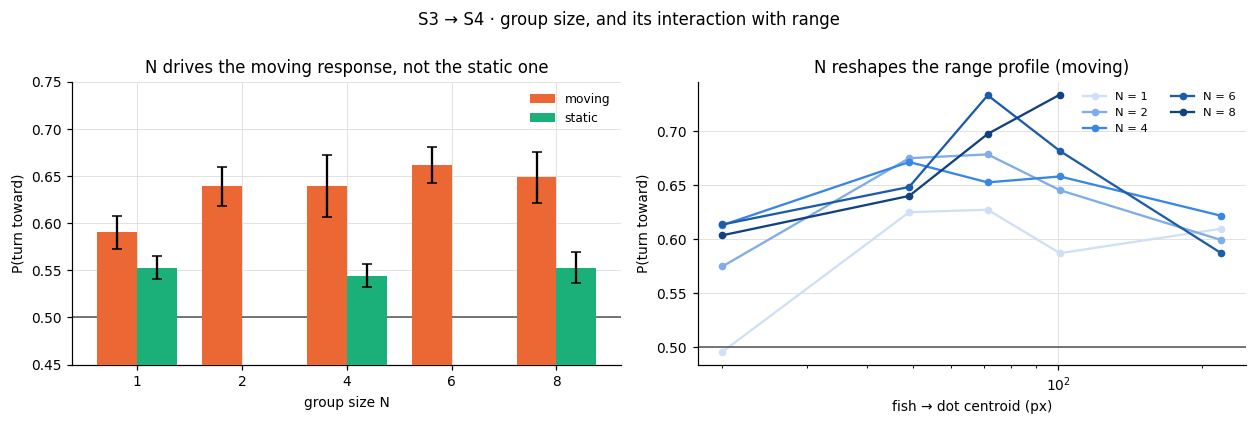

moving  N=1: 0.583  N=2: 0.635  N=4: 0.640  N=6: 0.663  N=8: 0.645
static  N=1: 0.556  N=4: 0.544  N=8: 0.551

per fish, N=8 minus N=1 (moving): mean +0.058, 13/15 fish positive


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
Ns = [1, 2, 4, 6, 8]
w = .38
for j, (c, col) in enumerate((("moving", ORANGE), ("static", AQUA))):
    xs, ms, es = [], [], []
    for i, N in enumerate(Ns):
        g = t[(t.cond == c) & (t.N == N)]
        per = g.groupby("fish_id").toward.agg(["mean", "size"])
        per = per[per["size"] >= 25]["mean"]
        if len(per) < 8:
            continue
        xs.append(i); ms.append(per.mean())
        es.append(1.96 * per.std(ddof=1) / np.sqrt(len(per)))
    ax[0].bar(np.array(xs) + (j - .5) * w, ms, w, yerr=es, capsize=3,
              color=col, label=c, zorder=3)
ax[0].axhline(.5, color=INK2, lw=1)
ax[0].set_xticks(range(len(Ns))); ax[0].set_xticklabels(Ns)
ax[0].set_xlabel("group size N"); ax[0].set_ylabel("P(turn toward)")
ax[0].set_ylim(.45, .75); ax[0].legend(fontsize=8)
ax[0].set_title("N drives the moving response, not the static one")

SEQ = ["#cfe0f6", "#7fade8", "#3987e5", "#1c5cab", "#104281"]
for i, N in enumerate(Ns):
    x, m, lo, hi = curve(t[(t.cond == "moving") & (t.N == N)],
                         np.array([0, 40, 60, 85, 120, 400]), min_fish=6)
    if len(x):
        ax[1].plot(x, m, "-o", color=SEQ[i], ms=4, label=f"N = {N}")
ax[1].axhline(.5, color=INK2, lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("fish → dot centroid (px)")
ax[1].set_ylabel("P(turn toward)"); ax[1].legend(fontsize=7.5, ncol=2)
ax[1].set_title("N reshapes the range profile (moving)")
for a_ in ax:
    a_.grid(color=GRID, lw=.6, zorder=0); a_.set_axisbelow(True)
fig.suptitle("S3 → S4 · group size, and its interaction with range", y=1.0)
fig.tight_layout(); plt.show()

for c in ("moving", "static"):
    v = {int(N): t[(t.cond == c) & (t.N == N)].toward.mean() for N in Ns
         if len(t[(t.cond == c) & (t.N == N)]) > 100}
    print(f"{c:<7} " + "  ".join(f"N={k}: {x:.3f}" for k, x in v.items()))
pf = t[t.cond == "moving"].groupby(["fish_id", "N"]).toward.mean().unstack()
dd = (pf[8] - pf[1]).dropna()
print(f"\nper fish, N=8 minus N=1 (moving): mean {dd.mean():+.3f}, "
      f"{int((dd > 0).sum())}/{len(dd)} fish positive")

Moving rises **0.583 → 0.663** from N=1 to N=6 (+0.058 per fish, **13/15** in the same
direction); static is flat at ~0.55 across N. And the effect is not a constant offset — at
N=1 the near field is at chance (0.509 inside 40 px) while at N=6–8 it is ~0.60, so **N
reshapes the range profile**. That is a `G·(nz·sin φ)` interaction, not an additive `nz`.

⚠ Static only ever ran at N ∈ {1, 4, 8}, so the static row of any N × condition contrast is
built on three levels, not five.

---

### Which to use

**S3** is the smallest representation that gets the shape of the range response right, and
S2 → S3 is the step with the largest measured consequence. **S4** is worth the extra five
columns only if group size is part of the question — the effect is real but modest, and
confined to moving blocks. **S1/S2** are honest baselines to ablate *against*, not to ship.

# Border representations

Two methods, explain simple and then motivation for basis with simple markdonw and plot (1 cell ecah)

---

## Border representation — `raw` (3) vs `basis` (9)

The same argument as S2 → S3, one level down. The wall block is
`fit_MLP_border.BORDER_COLS_RAW = (dnorm, sin ψ, cos ψ)`, where ψ is the bearing to the **dish
centre** and `dnorm = (R − r)/R` runs 0 at the wall to 1 at the centre. Under
`border_mode='basis'` the two bearing columns are replaced by a 4-knot softmax basis over
`log dnorm`, giving 9 columns.

| | dims | columns |
|---|---|---|
| `raw` | 3 | `dnorm`, `sin ψ`, `cos ψ` |
| `basis` | 9 | `dnorm`, `G·sin ψ` ×4, `G·cos ψ` ×4 — knots at dnorm **0.03, 0.10, 0.25, 0.55** |

Because Σⱼ Gⱼ = 1 the basis contains raw `sin ψ` exactly, so nothing is lost; and it
flat-extrapolates outside the knots, which matters at the near end where a sustained response
is required rather than a decay to zero.

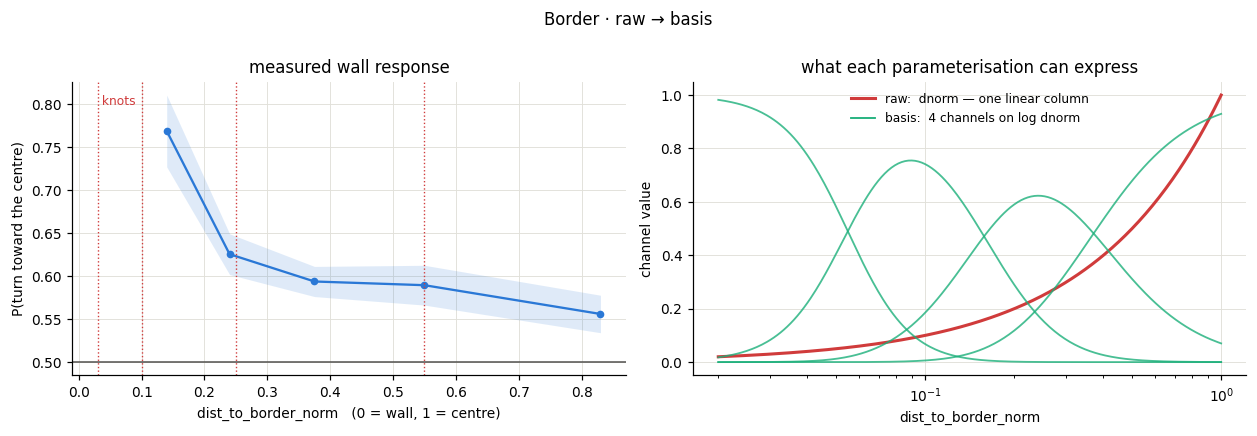

dnorm          P(toward centre)        n  fish > 0.5
0.05-0.10                 0.775      102         3/3
0.10-0.18                 0.762    1,936       14/14
0.18-0.30                 0.620    6,844       15/15
0.30-0.45                 0.591   11,465       15/15
0.45-0.65                 0.597   19,122       15/15
0.65-1.01                 0.574   22,307       13/15

bouts inside the innermost knot (dnorm < 0.03): 0
median dnorm 0.564, p5 0.200


In [ ]:
import fit_MLP_border as MB

t = d[d.active & (d.dtheta_deg.abs() > 10)].copy()
t["toward"] = (np.sign(t.dtheta_deg) == np.sign(t.wall_psi_rad)).astype(float)
E = np.array([0, .05, .10, .18, .30, .45, .65, 1.01])

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))

x, m, lo, hi = [], [], [], []
for a_, b_ in zip(E[:-1], E[1:]):
    g = t[t.dist_to_border_norm.between(a_, b_)]
    per = g.groupby("fish_id").toward.agg(["mean", "size"])
    per = per[per["size"] >= 20]["mean"]
    if len(per) < 5:
        continue
    se = per.std(ddof=1) / np.sqrt(len(per))
    x.append((a_ + b_) / 2); m.append(per.mean())
    lo.append(per.mean() - 1.96 * se); hi.append(per.mean() + 1.96 * se)
ax[0].plot(x, m, "-o", color=BLUE, ms=4)
ax[0].fill_between(x, lo, hi, color=BLUE, alpha=.15, lw=0)
ax[0].axhline(.5, color=INK2, lw=1)
for k in MB.BORDER_KNOTS:
    ax[0].axvline(k, color="#d03b3b", lw=.9, ls=":")
ax[0].text(MB.BORDER_KNOTS[0], .80, " knots", color="#d03b3b", fontsize=8)
ax[0].set_xlabel("dist_to_border_norm   (0 = wall, 1 = centre)")
ax[0].set_ylabel("P(turn toward the centre)")
ax[0].set_title("measured wall response")

dn = np.logspace(np.log10(0.02), 0, 300)
ax[1].plot(dn, dn, color="#d03b3b", lw=2, label="raw:  dnorm — one linear column")
G = MB.border_channels(dn, np.zeros_like(dn), mode="basis")
lr = np.log(np.clip(dn, MB.BORDER_MIN, None))
z = -0.5 * ((lr[:, None] - np.log(np.asarray(MB.BORDER_KNOTS))[None, :]) / MB.BORDER_W) ** 2
Gm = np.exp(z - z.max(1, keepdims=True)); Gm = Gm / Gm.sum(1, keepdims=True)
for j in range(Gm.shape[1]):
    ax[1].plot(dn, Gm[:, j], color=AQUA, lw=1.2, alpha=.8)
ax[1].plot([], [], color=AQUA, lw=1.2, label="basis:  4 channels on log dnorm")
ax[1].set_xscale("log")
ax[1].set_xlabel("dist_to_border_norm"); ax[1].set_ylabel("channel value")
ax[1].legend(fontsize=8); ax[1].set_title("what each parameterisation can express")
for a_ in ax:
    a_.grid(color=GRID, lw=.6, zorder=0); a_.set_axisbelow(True)
fig.suptitle("Border · raw → basis", y=1.0)
fig.tight_layout(); plt.show()

print(f"{'dnorm':<13}{'P(toward centre)':>18}{'n':>9}{'fish > 0.5':>12}")
for a_, b_ in zip(E[:-1], E[1:]):
    g = t[t.dist_to_border_norm.between(a_, b_)]
    if not len(g):
        continue
    per = g.groupby("fish_id").toward.agg(["mean", "size"])
    per = per[per["size"] >= 20]["mean"]
    print(f"{a_:.2f}-{b_:<8.2f}{g.toward.mean():>18.3f}{len(g):>9,}"
          f"{f'{int((per > .5).sum())}/{len(per)}':>12}")
print(f"\nbouts inside the innermost knot (dnorm < {MB.BORDER_KNOTS[0]}): "
      f"{int((t.dist_to_border_norm < MB.BORDER_KNOTS[0]).sum()):,}")
print(f"median dnorm {t.dist_to_border_norm.median():.3f}, "
      f"p5 {t.dist_to_border_norm.quantile(.05):.3f}")

**The response is a step, not a slope.** P(turn toward the centre) is **0.78 near the wall**,
holds to ~0.76 through dnorm 0.18, then drops sharply and flattens at **0.57–0.62** across the
whole interior. The transition sits around dnorm 0.18–0.30. A single linear `dnorm` column
(the red line) has to approximate that with a straight line — it can either match the wall
response or the interior baseline, not both. The basis puts its resolution exactly where the
curve bends.

It is also not one odd fish: **15/15** above chance in every interior bin, 14/14 in the
0.10–0.18 bin.

⚠ **Two of the four knots sit in a nearly empty region.** There are **zero** bouts inside
dnorm < 0.03, and only ~100 below 0.10, while the median bout is at dnorm 0.564 and p5 is 0.200.
So the innermost knot is unpopulated and the second is fit on ~100 bouts. That is not fatal —
the softmax normalisation makes the profile flat-extrapolate past the outermost populated knot
rather than collapsing to zero, which is the documented reason for using softmax rather than raw
Gaussians — but it does mean the effective resolution is ~2 knots, and the near-wall end of the
fitted profile rests on very little data. Worth remembering before reading a fitted near-wall
gain as a measurement.